# 8장. 작은 데이터 분석 프로젝트 완성하기

이 노트북은 데이터 점검, 전처리, 병합 검증, 완료 주문 기준 집계, 시각화, 보고서 작성을 하나의 재현 가능한 프로젝트로 연결합니다.


## 학습 목표

- 원본 데이터를 보존하며 전처리합니다.
- 주요 키 중복과 외래키 미매칭을 확인합니다.
- `validate`와 `indicator`를 사용한 병합 검증 원리를 확인합니다.
- 취소·환불 주문을 제외하고 완료 주문 기준 매출을 계산합니다.
- 고객 이름을 노출하지 않는 익명화 결과를 만듭니다.
- 결과 CSV, 그래프, Markdown 보고서를 재현 가능하게 저장합니다.


## 1. 프로젝트 루트와 출력 폴더 설정

VS Code에서 현재 작업 폴더가 프로젝트 루트 또는 `notebooks`일 수 있으므로 상위 폴더를 탐색합니다.


In [1]:
from pathlib import Path
import sys

import pandas as pd


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / 'requirements.txt').exists() and (candidate / 'scripts').exists():
            return candidate
    raise FileNotFoundError('프로젝트 루트 폴더를 찾을 수 없습니다.')


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
FIGURE_DIR = REPORT_DIR / 'figures'

for path in [PROCESSED_DIR, REPORT_DIR, FIGURE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('Python 실행 파일:', sys.executable)
print('프로젝트 루트:', PROJECT_ROOT)
print('원본 데이터 폴더:', RAW_DIR)
print('보고서 폴더:', REPORT_DIR)


Python 실행 파일: c:\dev\llm-data-analysis-course\.venv\Scripts\python.exe
프로젝트 루트: C:\dev\llm-data-analysis-course
원본 데이터 폴더: C:\dev\llm-data-analysis-course\data\raw
보고서 폴더: C:\dev\llm-data-analysis-course\reports


## 2. 프로젝트 함수 불러오기

중간 프로젝트의 공통 로직은 `src/` 모듈에 정리되어 있습니다. Notebook과 일괄 실행 스크립트가 같은 함수를 사용하므로 계산 기준이 어긋나는 문제를 줄일 수 있습니다.


In [2]:
from src.data_loader import load_sales_data
from src.preprocessing import (
    compare_shapes,
    preprocess_sales_data,
    save_processed_data,
    validate_relationships,
)
from src.midterm_project import (
    build_analysis_tables,
    build_interpretation_notes,
    build_key_duplicate_checks,
    build_midterm_report,
    create_project_figures,
    run_midterm_project,
    save_project_tables,
    summarize_datasets,
)


## 3. 원본 데이터 확인

파일이 없다면 프로젝트 루트에서 `python scripts/generate_sample_data.py`를 먼저 실행합니다.


In [3]:
raw_data = load_sales_data(RAW_DIR)

dataset_summary = summarize_datasets(raw_data)
display(dataset_summary)

for name, df in raw_data.items():
    print(f'\n===== {name} =====')
    print('shape:', df.shape)
    print('columns:', df.columns.tolist())
    print('missing values:', int(df.isna().sum().sum()))
    print('duplicated rows:', int(df.duplicated().sum()))


,dataset,rows,columns,missing_values,duplicated_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,5,0,0
3,order_items,764,5,0,0



===== customers =====
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
missing values: 0
duplicated rows: 0

===== products =====
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']
missing values: 0
duplicated rows: 0

===== orders =====
shape: (300, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']
missing values: 0
duplicated rows: 0

===== order_items =====
shape: (764, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']
missing values: 0
duplicated rows: 0


## 4. 원본을 보존하며 전처리

`preprocess_sales_data()`는 원본 DataFrame을 직접 수정하지 않고 전처리된 복사본을 반환합니다.


In [4]:
processed_data = preprocess_sales_data(raw_data)
processed_paths = save_processed_data(processed_data, PROCESSED_DIR)

preprocessing_comparison = compare_shapes(raw_data, processed_data)
display(preprocessing_comparison)

for path in processed_paths:
    print(path, 'OK' if path.exists() else 'MISSING')


,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,150,6,150,6
1,order_items,764,5,764,6
2,orders,300,5,300,7
3,products,100,4,100,4


C:\dev\llm-data-analysis-course\data\processed\customers_clean.csv OK
C:\dev\llm-data-analysis-course\data\processed\products_clean.csv OK
C:\dev\llm-data-analysis-course\data\processed\orders_clean.csv OK
C:\dev\llm-data-analysis-course\data\processed\order_items_clean.csv OK


## 5. 키 중복과 관계 점검

전체 행 중복뿐 아니라 고객·상품·주문·주문 상세의 식별 키 중복을 확인합니다. 외래키가 기준 테이블에 존재하지 않는 행도 확인합니다.


In [5]:
key_duplicate_checks = build_key_duplicate_checks(processed_data)
relationship_checks = validate_relationships(processed_data)

display(key_duplicate_checks)
display(relationship_checks)


,dataset,key,duplicate_count
0,customers,customer_id,0
1,products,product_id,0
2,orders,order_id,0
3,order_items,order_item_id,0


,check,invalid_count
0,orders.customer_id exists in customers.custome...,0
1,order_items.order_id exists in orders.order_id,0
2,order_items.product_id exists in products.prod...,0


## 6. 안전한 병합과 완료 주문 기준 집계

`build_analysis_tables()`는 다음 기준을 적용합니다.

- 주문 상세와 주문: `many_to_one`
- 완료 주문만 매출 집계에 포함
- 주문 상세와 상품: `many_to_one`
- 고객 집계와 고객 속성: `one_to_one`
- 병합 전후 행 수와 미매칭 건수 기록


In [6]:
analysis_tables = build_analysis_tables(processed_data)

display(analysis_tables['merge_checks'])
display(analysis_tables['amount_scope_summary'])


,merge,before_rows,after_rows,row_count_preserved,unmatched_count
0,order_id → orders,764,764,True,0
1,product_id → products,474,474,True,0
2,customer_id → customers,100,100,True,0


,scope,amount,detail_rows
0,all_order_items,255610000.0,764
1,completed_order_items,148990000.0,474
2,excluded_cancelled_or_refunded,106620000.0,290


## 7. 주요 결과 확인

아래 매출표는 모두 완료 주문 기준입니다. 주문 상태별 요약표는 전체 주문을 대상으로 합니다.


In [7]:
category_sales = analysis_tables['category_sales']
monthly_sales = analysis_tables['monthly_sales']
customer_sales = analysis_tables['customer_sales']
order_status_summary = analysis_tables['order_status_summary']

display(category_sales)
display(monthly_sales)
display(
    customer_sales[
        ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
    ].head(10)
)
display(order_status_summary)


,category,total_quantity,total_sales,sales_ratio
3,스포츠,295,31743000,21.31
5,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
1,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
0,도서,149,16389000,11.00
6,패션,111,10587000,7.11


,order_month,total_sales,order_count,avg_order_value
0,2025-09,2650000,5,530000.0
1,2025-10,16970000,19,893158.0
2,2025-11,11021000,13,847769.0
3,2025-12,22314000,24,929750.0
4,2026-01,13303000,16,831438.0
5,2026-02,5318000,7,759714.0
6,2026-03,17529000,24,730375.0
7,2026-04,11832000,17,696000.0
8,2026-05,16345000,18,908056.0
9,2026-06,14070000,18,781667.0


,customer_label,city,order_count,total_sales,avg_order_value
0,Customer 117,성남,5,4100000,820000.0
1,Customer 102,고양,4,3996000,999000.0
2,Customer 83,수원,4,3880000,970000.0
3,Customer 30,서울,5,3590000,718000.0
4,Customer 40,서울,4,3523000,880750.0
5,Customer 20,인천,2,3191000,1595500.0
6,Customer 3,성남,2,3178000,1589000.0
7,Customer 111,광주,3,3153000,1051000.0
8,Customer 66,서울,4,3093000,773250.0
9,Customer 147,부산,2,2990000,1495000.0


,order_status,order_count,order_ratio
0,completed,184,61.33
1,cancelled,64,21.33
2,refunded,52,17.33


## 8. 해석 메모와 결과 저장

관찰, 주의점, 다음 질문을 분리합니다. 고객 결과에는 실제 이름을 포함하지 않습니다.


In [8]:
interpretation_notes = build_interpretation_notes()
display(interpretation_notes)

saved_tables = save_project_tables(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
    REPORT_DIR,
)

for path in saved_tables:
    print(path.name, path.exists(), path.stat().st_size)


,analysis,observation,caution,next_question
0,카테고리별 완료 주문 매출,완료 주문 매출 비중이 높은 카테고리를 확인할 수 있습니다.,매출이 높은 이유가 판매 수량인지 단가인지 구분해야 합니다.,카테고리별 평균 판매 단가는 어떻게 다른가?
1,월별 완료 주문 매출,시간에 따른 완료 주문 매출의 증가와 감소를 확인할 수 있습니다.,프로모션이나 계절성이 원인이라고 단정할 수 없습니다.,주문 수와 평균 주문 금액 중 무엇이 변했는가?
2,고객별 완료 주문 구매 금액,완료 주문 구매 금액이 높은 고객군을 확인할 수 있습니다.,일회성 고액 구매와 반복 구매를 구분해야 합니다.,최근 구매일과 구매 빈도는 어떻게 다른가?
3,주문 상태별 주문 수,"완료, 취소, 환불 주문의 분포를 확인할 수 있습니다.",주문 상태의 정의와 처리 기준을 확인해야 합니다.,취소율과 환불률은 월별로 달라지는가?


ch08_dataset_summary.csv True 138
ch08_preprocessing_comparison.csv True 156
ch08_key_duplicate_checks.csv True 128
ch08_relationship_checks.csv True 184
ch08_merge_checks.csv True 187
ch08_amount_scope_summary.csv True 149
ch08_category_sales.csv True 254
ch08_monthly_sales.csv True 439
ch08_customer_sales.csv True 4333
ch08_order_status_summary.csv True 101
ch08_interpretation_notes.csv True 1036


## 9. 그래프 생성

그래프 제목에도 완료 주문 기준임을 표시합니다.


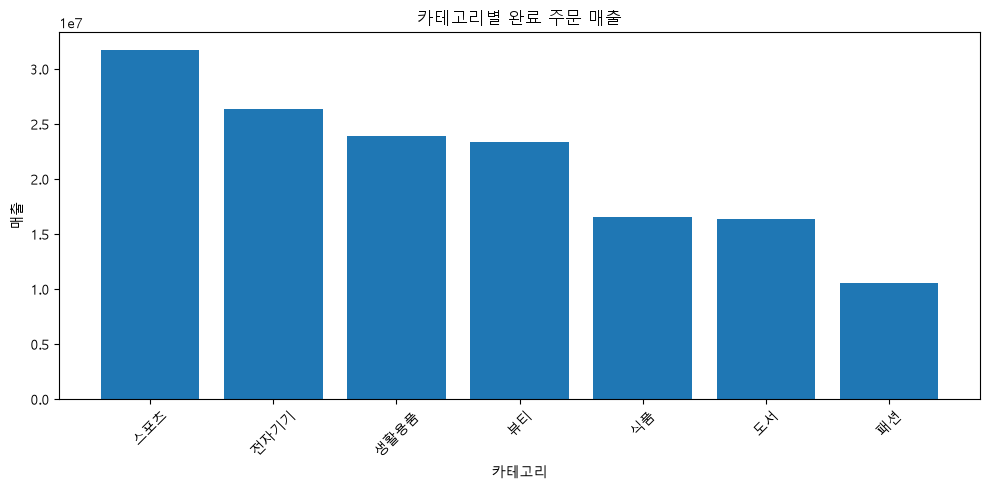

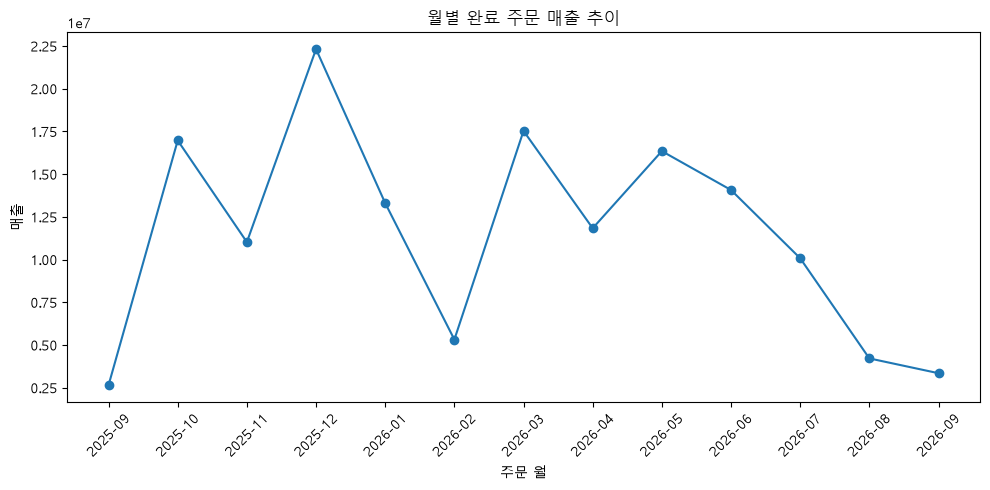

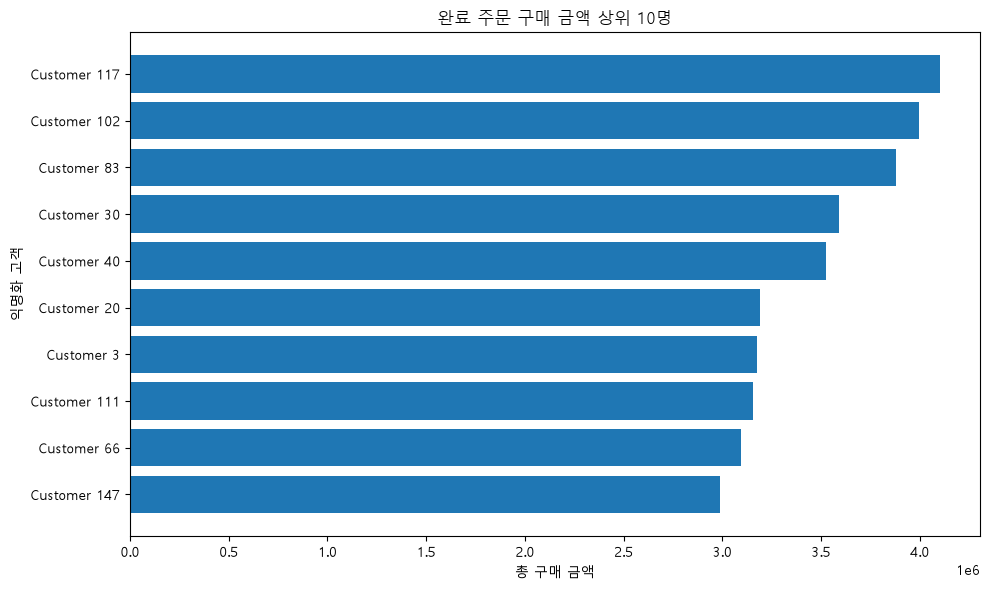

ch08_category_sales.png True 25830
ch08_monthly_sales.png True 81858
ch08_top_customers.png True 45556


In [9]:
saved_figures = create_project_figures(
    analysis_tables,
    FIGURE_DIR,
    show=True,
)

for path in saved_figures:
    print(path.name, path.exists(), path.stat().st_size)


## 10. Markdown 보고서 생성

보고서는 완료 주문 기준, 병합 검증, 익명화 원칙을 명시합니다.


In [10]:
report_text = build_midterm_report(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
)

report_path = REPORT_DIR / 'ch08_midterm_report.md'
report_path.write_text(report_text, encoding='utf-8')

print('보고서 저장:', report_path)
print(report_text[:1500])


보고서 저장: C:\dev\llm-data-analysis-course\reports\ch08_midterm_report.md
# Chapter 8 중간 프로젝트 보고서

## 1. 분석 목적

온라인 쇼핑몰 데이터를 사용해 완료 주문 기준 매출 현황과 고객 구매 패턴을 분석했습니다.

## 2. 분석 기준

- 매출은 `order_status == "completed"`인 주문만 포함했습니다.
- 취소·환불 주문을 포함한 금액은 전체 주문 상세 금액으로 구분했습니다.
- 고객 이름은 결과와 보고서에서 제외하고 익명화 라벨을 사용했습니다.
- 병합은 관계 검증과 행 수·미매칭 확인을 수행했습니다.

## 3. 데이터 개요

```text
    dataset  rows  columns  missing_values  duplicated_rows
  customers   150        6               0                0
   products   100        4               0                0
     orders   300        5               0                0
order_items   764        5               0                0
```

## 4. 전처리 전후 비교

```text
    dataset  rows_raw  columns_raw  rows_processed  columns_processed
  customers       150            6             150                  6
order_items       764            5             764                  6
     orders       300            5             300                  7
   products       100        

## 11. 전체 파이프라인 재실행

단계별 결과를 확인한 뒤에는 같은 함수를 사용하는 전체 파이프라인으로 재현성을 점검합니다.


In [11]:
project_result = run_midterm_project(
    raw_dir=RAW_DIR,
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    figure_dir=FIGURE_DIR,
    show_figures=False,
)

project_result['report_path']


WindowsPath('C:/dev/llm-data-analysis-course/reports/ch08_midterm_report.md')

## 12. 최종 산출물 검증

필수 파일이 존재하고 비어 있지 않은지 확인합니다.


In [12]:
expected_outputs = [
    REPORT_DIR / 'ch08_midterm_report.md',
    REPORT_DIR / 'ch08_dataset_summary.csv',
    REPORT_DIR / 'ch08_preprocessing_comparison.csv',
    REPORT_DIR / 'ch08_key_duplicate_checks.csv',
    REPORT_DIR / 'ch08_relationship_checks.csv',
    REPORT_DIR / 'ch08_merge_checks.csv',
    REPORT_DIR / 'ch08_amount_scope_summary.csv',
    REPORT_DIR / 'ch08_category_sales.csv',
    REPORT_DIR / 'ch08_monthly_sales.csv',
    REPORT_DIR / 'ch08_customer_sales.csv',
    REPORT_DIR / 'ch08_order_status_summary.csv',
    FIGURE_DIR / 'ch08_category_sales.png',
    FIGURE_DIR / 'ch08_monthly_sales.png',
    FIGURE_DIR / 'ch08_top_customers.png',
]

all_outputs_valid = True
for path in expected_outputs:
    valid = path.exists() and path.stat().st_size > 0
    all_outputs_valid &= valid
    print(path.name, 'OK' if valid else 'MISSING OR EMPTY')

print('전체 산출물 검증:', all_outputs_valid)


ch08_midterm_report.md OK
ch08_dataset_summary.csv OK
ch08_preprocessing_comparison.csv OK
ch08_key_duplicate_checks.csv OK
ch08_relationship_checks.csv OK
ch08_merge_checks.csv OK
ch08_amount_scope_summary.csv OK
ch08_category_sales.csv OK
ch08_monthly_sales.csv OK
ch08_customer_sales.csv OK
ch08_order_status_summary.csv OK
ch08_category_sales.png OK
ch08_monthly_sales.png OK
ch08_top_customers.png OK
전체 산출물 검증: True


## 13. 개인정보와 결과 일치 검증

고객 이름이 결과표에 포함되지 않았는지 확인하고, 카테고리 매출 합계와 완료 주문 매출 합계가 일치하는지 확인합니다.


In [13]:
assert 'name' not in customer_sales.columns

completed_total = analysis_tables['completed_order_sales']['line_total'].sum()
category_total = category_sales['total_sales'].sum()
monthly_total = monthly_sales['total_sales'].sum()
customer_total = customer_sales['total_sales'].sum()

print('완료 주문 매출:', completed_total)
print('카테고리 합계:', category_total)
print('월별 합계:', monthly_total)
print('고객별 합계:', customer_total)

assert completed_total == category_total == monthly_total == customer_total
print('결과 합계 일치 검증 완료')


완료 주문 매출: 148990000
카테고리 합계: 148990000
월별 합계: 148990000
고객별 합계: 148990000
결과 합계 일치 검증 완료


## 14. LLM 검토 프롬프트 예시

```text
온라인 쇼핑몰 중간 프로젝트 결과를 검토해 주세요.

분석 기준:
- 매출은 order_status가 completed인 주문만 포함
- 고객 이름은 제외하고 익명화 라벨 사용
- 병합은 validate와 indicator로 검증

검토 항목:
1. 분석 질문과 지표가 연결되어 있는가?
2. 취소·환불 주문이 매출에 포함되지 않았는가?
3. 병합 후 행 증가 또는 미매칭을 확인했는가?
4. 관찰과 원인 가설을 구분했는가?
5. 개인정보가 불필요하게 노출되지 않았는가?
6. Notebook, CSV, 그래프, 보고서의 수치가 일치하는가?

데이터에 없는 원인은 단정하지 말고,
필수 수정과 권장 개선을 구분해 주세요.
```


## 15. 실습 과제

1. 카테고리별 평균 판매 단가를 추가합니다.
2. 월별 취소율과 환불률을 계산합니다.
3. 고객별 최근 구매일과 구매 빈도를 추가합니다.
4. 전체 주문 상세 금액과 완료 주문 매출의 차이를 해석합니다.
5. 결과 합계가 모든 집계표에서 일치하는지 검증 코드를 추가합니다.
6. LLM 활용 내역과 실제 반영 여부를 표로 작성합니다.


In [14]:
# 과제 1. 카테고리별 평균 판매 단가를 추가합니다.
category_sales['avg_unit_price'] = (category_sales['total_sales'] / category_sales['total_quantity']).round(0)
display(category_sales)

,category,total_quantity,total_sales,sales_ratio,avg_unit_price
3,스포츠,295,31743000,21.31,107603.0
5,전자기기,259,26400000,17.72,101931.0
2,생활용품,272,23915000,16.05,87923.0
1,뷰티,223,23383000,15.69,104857.0
4,식품,133,16573000,11.12,124609.0
0,도서,149,16389000,11.00,109993.0
6,패션,111,10587000,7.11,95378.0


In [15]:
# 과제 2. 월별 취소율과 환불률을 계산합니다.
monthly_status_rate = (
    pd.crosstab(processed_data['orders']['order_month'], processed_data['orders']['order_status'], normalize='index')
    .mul(100).round(1)[['cancelled', 'refunded']]
    .rename(columns={'cancelled': 'cancel_rate', 'refunded': 'refund_rate'})
)
display(monthly_status_rate)

order_status,cancel_rate,refund_rate
order_month,,
2025-09,20.0,30.0
2025-10,22.2,7.4
2025-11,19.0,19.0
2025-12,25.7,5.7
2026-01,24.1,20.7
2026-02,37.5,18.8
2026-03,14.7,14.7
2026-04,14.3,25.0
2026-05,29.6,3.7


In [16]:
# 과제 3. 고객별 최근 구매일과 구매 빈도를 추가합니다.
customer_recency = (
    analysis_tables['completed_order_sales']
    .groupby('customer_id', as_index=False)
    .agg(last_order_date=('order_date', 'max'), purchase_count=('order_id', 'nunique'))
)
customer_recency['customer_label'] = 'Customer ' + customer_recency['customer_id'].astype(str)
customer_sales = customer_sales.merge(customer_recency.drop(columns='customer_id'), on='customer_label', how='left')
display(customer_sales[['customer_label', 'last_order_date', 'purchase_count', 'total_sales']].head(10))
is_repeat = customer_sales['purchase_count'] >= 2
print('반복 구매 고객:', is_repeat.sum(), '명 / 매출 비중:', round(customer_sales.loc[is_repeat, 'total_sales'].sum() / completed_total * 100, 2), '%')

,customer_label,last_order_date,purchase_count,total_sales
0,Customer 117,2026-08-08,5,4100000
1,Customer 102,2026-04-29,4,3996000
2,Customer 83,2026-09-05,4,3880000
3,Customer 30,2026-06-12,5,3590000
4,Customer 40,2026-07-23,4,3523000
5,Customer 20,2026-04-01,2,3191000
6,Customer 3,2026-01-16,2,3178000
7,Customer 111,2026-09-06,3,3153000
8,Customer 66,2026-07-31,4,3093000
9,Customer 147,2026-07-06,2,2990000


반복 구매 고객: 56 명 / 매출 비중: 74.82 %


In [17]:
# 과제 4. 전체 주문 상세 금액과 완료 주문 매출의 차이를 해석합니다.
status_amount = analysis_tables['order_sales'].groupby('order_status')['line_total'].sum()
display(status_amount)
print('전체 주문 상세 금액 - 완료 주문 매출 =', f"{status_amount.sum() - status_amount['completed']:,}")

order_status
cancelled     62181000
completed    148990000
refunded      44439000
Name: line_total, dtype: int64

전체 주문 상세 금액 - 완료 주문 매출 = 106,620,000


### 과제 4 해석
- 전체 주문 상세 금액(255,610,000원)과 완료 주문 매출(148,990,000원)의 차이 106,620,000원은 주문은 들어왔지만 취소 또는 환불되어 매출로 확정되지 않은 금액이다. 이 중 취소가 62,181,000원, 환불이 44,439,000원이다.
- 차이는 전체 주문 상세 금액의 41.71%이다. 전체 금액을 그대로 매출로 쓰면 실제 완료 주문 매출보다 약 71.6% 크게 보고된다. 따라서 매출은 모두 완료 주문 기준으로 계산했다.
- 취소와 환불의 업무 정의(예: 결제 전 취소인지, 배송 후 반품인지)와 사유는 데이터에 없다. 주문 단위 상태만 있어서 부분 환불이나 취소 후 재주문 여부도 알 수 없다. 금액이 큰 주문에서 취소/환불이 많은 이유는 이 데이터로 단정할 수 없다.

In [18]:
# 과제 5. 결과 합계가 모든 집계표에서 일치하는지 검증 코드를 추가합니다.
totals = {
    '카테고리별': category_sales['total_sales'].sum(),
    '월별': monthly_sales['total_sales'].sum(),
    '고객별': customer_sales['total_sales'].sum(),
    '상태별 중 completed': status_amount['completed'],
}
for name, value in totals.items():
    print(f'{name} 합계: {value:,} / 완료 주문 매출과 일치: {value == completed_total}')
assert all(value == completed_total for value in totals.values())
print('모든 집계표 합계 일치')

카테고리별 합계: 148,990,000 / 완료 주문 매출과 일치: True
월별 합계: 148,990,000 / 완료 주문 매출과 일치: True
고객별 합계: 148,990,000 / 완료 주문 매출과 일치: True
상태별 중 completed 합계: 148,990,000 / 완료 주문 매출과 일치: True
모든 집계표 합계 일치


### 과제 6. LLM 활용 내역과 실제 반영 여부
| 활용 내용 | LLM 제안 | 반영 여부 | 사람이 수정·확인한 내용 |
|---|---|---|---|
| 분석 질문 설계 | 해석 메모의 다음 질문과 실습 과제를 연결한 질문 3개 | 반영 | 데이터와 질문의 내용이 일치하는지 확인 |
| 실습 과제 코드 (1차) | 준비 셀 + 순위·상관계수·구간표 출력 | 보류 | 불필요한 출력이 많아 사용하지 않음 |
| 실습 과제 코드 (2차) | 기존 결과표를 쓰는 코드 | 수정 후 반영 | analysis_tables 키/컬럼을 직접 확인하고, 과제 목표만 남기도록 간소화 요청 |
| 과제 4 해석 | 차이의 의미·규모·건수 대비 금액 비중·한계 | 반영 | 노트북 6,7번 출력과 수치 대조 |
| 검증 | 과제 5 합계 검증 코드 | 반영 | 실행 결과 모든 합계 일치 확인 |

## 정리

이번 장에서는 원본 데이터 확인, 전처리, 키 관계 점검, 병합 검증, 완료 주문 기준 매출 계산, 익명화, 시각화, 보고서 생성, 산출물 검증을 하나의 프로젝트로 연결했습니다. 다음 장부터는 이 분석 기반 위에서 머신러닝으로 확장합니다.


# Assignment 마크다운

# Chapter 08 답안 양식. 작은 데이터 분석 프로젝트 완성하기

> 이 내용을 `chapter08.ipynb`의 Markdown 셀로 작성합니다.

## 제출 정보
- 이름: 배성윤
- GitHub ID: aeuyui
- 작성일: 2026-11-04
- 최종 Notebook URL: https://github.com/aeuyui/llm-data-analysis-study/blob/main/chapter08/chapter08.ipynb

## 1. 프로젝트 질문
### 분석 질문
1. completed 매출은 어떤 카테고리에서 나오고, 카테고리 간 차이는 판매 수량과 단가 중 무엇과 함께 나타나는가?
   - 1-1. 카테고리별 completed 매출과 비중은 어떻게 다른가?
   - 1-2. 카테고리별 평균 판매 단가(매출 / 수량)는 어떻게 다른가? (실습 과제 1)
2. 월별 completed 매출은 어떻게 변했고, 매출이 낮은 달은 주문 수 감소와 취소·환불 증가 중 어느 쪽과 함께 나타나는가?
   - 2-1. 월별 completed 매출, 주문 수, 평균 주문 금액은 어떻게 변하는가?
   - 2-2. 월별 취소율과 환불률은 달라지는가? (실습 과제 2)
   - 2-3. 전체 주문 상세 금액과 completed 매출의 차이는 얼마이고, 무엇을 뜻하는가? (실습 과제 4)
3. completed 매출은 반복 구매 고객과 한 번 구매한 고객 중 어디에서 주로 나오는가?
   - 3-1. 고객별 completed 주문 수, 구매 금액, 평균 주문 금액은 어떻게 분포하는가?
   - 3-2. 고객별 최근 구매일과 구매 빈도는 어떻게 다른가? (실습 과제 3)

### 분석 범위
- 분석 대상: 온라인 쇼핑몰 샘플 데이터(고객 150명, 상품 100개, 주문 300건, 주문 상세 764행)
- 기간: 2025-09 ~ 2026-09 주문(13개월). 첫 달과 마지막 달은 일부 기간만 포함됨.
- 금액 범위: 매출은 order_status가 completed인 주문만 포함(주문 184건, 주문 상세 474행). 취소/환불 주문(290행)은 매출에서 제외.
- 상태 분석 범위: 취소율/환불률과 주문 상태 분포는 전체 주문 300건을 대상으로 한다.
- 고객 범위: completed 주문이 있는 고객 100명. 고객 이름 대신 익명화 라벨(Customer ID)을 사용함.

### 사용할 데이터와 지표
| 질문 | 데이터 | 지표 |
| --- | --- | --- |
| 1 | order_items, orders, products (completed 주문 상세와 상품 병합) | 카테고리별 total_sales, sales_ratio, total_quantity, 평균 판매 단가 |
| 2 | orders, order_items (주문 월 기준) | 월별 total_sales, order_count, avg_order_value, 취소율, 환불률, 전체 금액 대비 completed 금액 |
| 3 | orders, order_items, customers (completed 주문의 고객 집계와 고객 속성 병합) | 고객별 order_count, total_sales, avg_order_value, 최근 구매일, 구매 빈도, 반복/단발 고객의 매출 비중 |

### 완료 기준
- 공통: 카테고리/월별/고객별 매출 합계가 모두 completed 원본 합계와 같고(실습 과제 5), 병합 전후 행 수가 유지됨. 미매칭 0건. 고객 결과에 이름 출력 안됨.
- 질문 1: 7개 카테고리의 매출, 비중, 평균 판매 단가를 계산하고, 매출 순위와 수량 순위가 다른 카테고리를 수치로 설명한다.
- 질문 2: 13개월이 누락 없이 있고, 월별 completed/취소/환불 비율의 합이 100%이다. 매출이 낮은 달에 주문 수와 상태 비율이 어떻게 달랐는지 비교하고, 일부 기간만 포함된 달은 따로 표시한다.
- 질문 3: 고객 100명의 합계가 completed 합계와 같고, 반복 구매(2회 이상) 고객과 1회 구매 고객의 매출 비중을 계산한다. 최근 구매일은 기준일을 밝혀 계산한다.

## 2. 입력 데이터 검증
- 사용 파일: 원본 data/raw의 customers, products, orders, order_items csv 4개를 불러와 preprocess_sales_data()로 전처리하고, data/processed의 *_clean.csv 4개로 저장했다.
- shape: 원본 customers (150,6), products (100,4), orders (300,5), order_items (764,5) -> 처리 후 (150,6), (100,4), (300,7), (764,6). 행 수는 변하지 않았고, orders에 주문 월 등 파생 컬럼 2개, order_items에 line_total 1개가 추가됨.
- 결측/중복 핵심 결과: 원본 4개 파일 모두 결측 0, 전체 행 중복 0이다. 처리 후 고유 키(customer_id, product_id, order_id, order_item_id) 중복도 모두 0이다.
- PK/FK 확인: orders.customer_id -> customers, order_items.order_id -> orders, order_items.product_id -> products 세 관계 모두 기준 테이블에 없는 값이 0건이다. [주문 상세 -> 주문 764행], [completed 주문 상세 -> 상품 474행], [고객 집계 -> 고객 속성 100행]도 모두 병합 전후 행 수가 같고 미매칭이 0건이다. 월별 completed 주문 수의 합(184건)이 completed 주문 수(184건)와 같아, 주문 상세가 없는 completed 주문도 없다.
- 금액 범위 정의: 매출은 order_status가 completed인 주문의 line_total(수량x단가) 합계로 정의. 전체 주문 상세 금액 255,610,000원(764행) 중 completed 매출은 148,990,000원이고, 취소·환불로 제외한 금액은 106,620,000원이다.

![입력 데이터 검증](images/step02_data_validation(1).png)

![입력 데이터 검증](images/step02_data_validation(2).png)

![입력 데이터 검증](images/step02_data_validation(3).png)

### 나의 해석과 판단
- 결측, 중복, 키 관계, 병합 행 수가 모두 정상이어서 데이터 구조에는 문제 없었다. 병합으로 행이 늘거나 사라지지 않았으므로 이후 집계에서 오류가 발생할 위험이 적다.
- 전체 주문 상세 금액의 약 42%(106,620,000원)가 취소/환불 주문이라, 범위를 밝히지 않으면 매출이 크게 과대평가된다. 따라서 모든 매출 집계를 completed 기준으로 통일했다.
- 노트북이 원본에서 다시 전처리했는데도 5장과 같은 결과가 나왔으므로, 전처리 과정이 재현되었다고 판단된다.

### 한계와 추가 확인 사항
- 이번 검증은 구조(결측, 중복, 키, 행 수) 중심이다. 0 이하 가격/수량, 주문 상세의 unit_price와 price의 일치 여부, 가입일과 주문일의 선후 관계 같은 값의 의미는 8장에서 다시 확인하지 않았다(가격/수량 범위는 5장에서 확인함).
- 결측은 원본 기준으로만 출력했고, 처리 후 데이터의 결측은 다시 출력하지 않았다.
- 고객 분석은 completed 주문 고객 100명만 대상이며, 나머지 50명은 포함되지 않는다.
- 샘플 데이터라서 결측·중복이 없었지만, 실제 데이터에서도 같은 결과가 나온다고 볼 수 없다.

## 3. 핵심 EDA 결과
카테고리별·월별·고객별 매출 합계와 주문 상태별 금액 중 completed 금액이 모두 완료 주문 매출 148,990,000원과 같다(실습 과제 5).

### 결과 1
- 수치/표: completed 기준 카테고리별 매출과 평균 판매 단가(실습 과제 1)

| 카테고리 | 매출(원) | 비중(%) | 판매 수량 | 평균 판매 단가(원) |
|---|---:|---:|---:|---:|
| 스포츠 | 31,743,000 | 21.31 | 295 | 107,603 |
| 전자기기 | 26,400,000 | 17.72 | 259 | 101,931 |
| 생활용품 | 23,915,000 | 16.05 | 272 | 87,923 |
| 뷰티 | 23,383,000 | 15.69 | 223 | 104,857 |
| 식품 | 16,573,000 | 11.12 | 133 | 124,609 |
| 도서 | 16,389,000 | 11.00 | 149 | 109,993 |
| 패션 | 10,587,000 | 7.11 | 111 | 95,378 |

- 결과 관찰: 판매 수량은 카테고리마다 111~295개로 약 2.7배 차이가 나지만, 평균 판매 단가는 87,923~124,609원으로 약 1.4배 차이이다. 매출 순위는 판매 수량 순위와 거의 같다. 예외로 식품은 평균 판매 단가가 가장 높아 판매 수량은 6위인데 매출은 5위이고, 생활용품은 단가가 가장 낮아 판매 수량은 2위인데 매출은 3위이다.
- 나의 해석과 판단: 카테고리 간 매출 차이는 주로 판매 수량의 차이와 함께 나타나고, 단가는 순위를 한 칸 정도 바꾸는 정도이다.
- 업무·분석적 의미: 카테고리 매출을 볼 때는 판매 수량을 먼저 확인하는 것이 효율적이다. 다만 식품처럼 단가가 높은 카테고리는 적은 수량으로도 매출이 크므로, 수량만으로 성과를 판단할 수 없다.
- 한계: 평균 판매 단가는 많이 팔린 상품의 가격대에 따라 달라지는 값이며, 할인 정보가 없어 단가 차이의 이유는 알 수 없다. 카테고리마다 상품 수가 달라 총매출에는 상품 수의 영향도 있다.

### 결과 2
- 수치/표: 월별 completed 매출(노트북 7번)과 월별 취소율/환불률(실습 과제 2)

| 월 | completed 매출(원) | completed 주문 | 취소율(%) | 환불률(%) |
|---|---:|---:|---:|---:|
| 2025-09* | 2,650,000 | 5 | 20.0 | 30.0 |
| 2025-10 | 16,970,000 | 19 | 22.2 | 7.4 |
| 2025-11 | 11,021,000 | 13 | 19.0 | 19.0 |
| 2025-12 | 22,314,000 | 24 | 25.7 | 5.7 |
| 2026-01 | 13,303,000 | 16 | 24.1 | 20.7 |
| 2026-02 | 5,318,000 | 7 | 37.5 | 18.8 |
| 2026-03 | 17,529,000 | 24 | 14.7 | 14.7 |
| 2026-04 | 11,832,000 | 17 | 14.3 | 25.0 |
| 2026-05 | 16,345,000 | 18 | 29.6 | 3.7 |
| 2026-06 | 14,070,000 | 18 | 15.4 | 15.4 |
| 2026-07 | 10,076,000 | 15 | 8.0 | 32.0 |
| 2026-08 | 4,214,000 | 5 | 37.5 | 31.2 |
| 2026-09* | 3,348,000 | 3 | 16.7 | 33.3 |
| 전체 | 148,990,000 | 184 | 21.33 | 17.33 |

\* 일부 기간만 포함된 달

전체 주문 상세 금액 255,610,000원 중 completed 매출은 148,990,000원이고, 차이 106,620,000원(41.71%)은 취소 62,181,000원과 환불 44,439,000원이다(실습 과제 4).

- 결과 관찰:
  - 한 달 전체가 포함된 달 중 completed 매출이 가장 낮은 2026-08(4,214,000원)과 2026-02(5,318,000원)은 취소율이 가장 높은 두 달이다(각 37.5%). 2026-08은 환불률도 31.2%로 높아, 취소율과 환불률의 합(68.7%)이 13개월 중 가장 높다.
  - 취소와 환불은 같은 방향으로 움직이지 않는다. 2026-05는 취소율 29.6%, 환불률 3.7%이고, 2026-07은 취소율 8.0%, 환불률 32.0%이다.
  - 금액으로는 취소가 환불보다 크다. 취소/환불 주문 1건의 평균 금액은 취소 약 970,000원, 환불 약 850,000원으로, completed 주문보다 크다.
- 나의 해석과 판단: completed 매출이 가장 낮은 두 달은 취소율이 가장 높은 달과 겹쳐 주문이 적은 것과 취소가 많은 것이 함께 나타난다. 반면 환불률이 가장 높은 2026-07은 매출이 최하위가 아니어서, 취소와 환불은 따로 보아야 한다고 판단했다. 어느 쪽이 매출을 더 낮췄는지, 왜 그런지는 이 데이터로 단정할 수 없다.
- 업무·분석적 의미: 매출이 낮은 달을 볼 때 주문 수와 함께 취소율을 확인해야 한다. 2026-02와 2026-08의 취소 주문, 2026-07의 환불 주문은 사유와 상품을 확인할 가치가 있다. 취소/환불 금액이 전체의 40%를 넘으므로 보고서에는 반드시 completed 기준을 밝혀야 한다.
- 한계: 월별 주문이 적어 비율이 몇 건에 크게 흔들린다. 2025-09와 2026-09는 일부 기간만 포함되어 비교에서 제외했다. 취소/환불의 업무 정의와 사유, 부분 환불 여부는 데이터에 없다.

### 결과 3
- 수치/표: completed 기준 구매 금액 상위 10명 고객의 구매 빈도와 최근 구매일(실습 과제 3)

| 고객 | 구매 횟수 | 구매 금액(원) | 최근 구매일 |
|---|---:|---:|---|
| Customer 117 | 5 | 4,100,000 | 2026-08-08 |
| Customer 102 | 4 | 3,996,000 | 2026-04-29 |
| Customer 83 | 4 | 3,880,000 | 2026-09-05 |
| Customer 30 | 5 | 3,590,000 | 2026-06-12 |
| Customer 40 | 4 | 3,523,000 | 2026-07-23 |
| Customer 20 | 2 | 3,191,000 | 2026-04-01 |
| Customer 3 | 2 | 3,178,000 | 2026-01-16 |
| Customer 111 | 3 | 3,153,000 | 2026-09-06 |
| Customer 66 | 4 | 3,093,000 | 2026-07-31 |
| Customer 147 | 2 | 2,990,000 | 2026-07-06 |

- 결과 관찰: 전체로 보면 completed 구매 고객 100명 중 2회 이상 구매한 56명이 매출의 74.82%를 차지한다(6장 과제 5 결과). 구매 금액 상위 10명은 모두 2~5회 구매한 반복 구매 고객이고, 이들의 구매 금액 합계 34,694,000원은 completed 매출의 약 23.3%이다. 상위 10명 중 6명은 최근 구매일이 2026-07 이후이지만, Customer 3, 20, 102는 데이터의 마지막 주문일(2026-09-13)보다 4개월 이상 전에 마지막으로 구매했다.
- 나의 해석과 판단: 매출 상위 고객이 모두 반복 구매 고객이고 반복 구매 고객이 매출의 약 3/4을 차지하므로, 이 데이터에서는 반복 구매가 매출의 중심이라고 판단했다. 다만 상위 고객 중에도 최근 구매가 오래된 고객이 있어, 과거 구매 금액만으로 지금도 핵심 고객이라고 볼 수는 없다.
- 업무·분석적 의미: 반복 구매 고객을 유지하는 것이 매출 유지와 직접 연결된다. Customer 3, 20, 102처럼 구매 금액이 크지만 최근 구매가 오래된 고객은 업무적으로 확인할 우선 대상이다.
- 한계: 관측 기간이 약 1년밖에 되지 않아 구매 주기가 긴 고객은 오래 구매하지 않은 것처럼 보일 수 있다. 최근 구매일만으로 고객이 떠났는지 판단할 수 없고, completed 주문이 없는 고객 50명은 분석에서 빠졌다.

## 4. 대표 시각화
![대표 그래프 1](images/graph01.png)
![대표 그래프 2](images/graph02.png)

### 그래프 선택 이유
- 대표 그래프 1(카테고리별 완료 주문 매출, 막대그래프): 질문 1에 답하는 그래프이다. 순서가 없는 7개 카테고리의 매출 크기를 비교하므로 막대그래프를 선택했고, 매출 내림차순으로 정렬되어 있어 상위/하위 카테고리를 바로 읽을 수 있다. 스포츠가 가장 높고 패션이 가장 낮으며, 생활용품과 뷰티, 식품과 도서는 거의 같은 수준임을 확인할 수 있다.
- 대표 그래프 2(월별 완료 주문 매출 추이, 선그래프): 질문 2에 답하는 그래프이다. 13개월의 시간 순서와 증감 흐름을 보여 주므로 선그래프를 선택했다. 2025-12가 가장 높고, 2026-02와 2026-08에 크게 낮아지며, 2026-05부터 2026-08까지 3개월 연속으로 감소하는 흐름을 확인할 수 있다.
- 구매 금액 상위 10명 그래프(노트북 9번)는 상위 고객만 보여 주어 반복 구매 고객과 1회 구매 고객을 비교하는 질문 3에 답하기에는 부족하여 대표 그래프로 선택하지 않았다. 질문 3은 실습 과제 3의 표로 답했다.

### 그래프와 원본 집계값 일치 여부
- 두 그래프는 노트북 7번의 category_sales와 monthly_sales로 그려졌고, 제목에 "완료 주문"이 표시되어 있다.
- 그래프의 막대 순서와 높이(예: 스포츠 약 3,174만 원, 패션 약 1,059만 원), 선의 최고점(2025-12, 약 2,231만 원)과 최저점(2025-09, 약 265만 원)이 집계표와 같다.
- 집계표의 합계는 카테고리별/월별 모두 완료 주문 매출 148,990,000원과 같다(노트북 13번, 실습 과제 5).
- 다만 그래프는 src/midterm_project.py의 함수로 그려져서, 막대·선의 값을 코드로 직접 대조하지는 않았고 눈으로 대조했다.

### 그래프만으로 말할 수 없는 것
- 원인: 카테고리 매출 차이나 프로모션, 재고, 배송 등과 같은 월별 감소의 원인은 그래프에 없다.
- 수량과 단가: 막대그래프는 매출 차이가 판매 수량 때문인지 단가 때문인지 보여 주지 않는다.
- 취소/환불의 영향: 두 그래프는 completed 매출만 보여 주므로, 그래프만으로는 매출이 낮은 달에 주문 자체가 적었는지 취소/환불이 많았는지 구분할 수 없다.
- 일부 기간만 포함된 달: 2025-09와 2026-09는 한 달 전체가 아니라서 낮게 보이지만, 그래프에는 표시되어 있지 않다.
- 축 표시의 한계: 그래프 2의 y축은 0이 아니라 약 200만 원 부근에서 시작해 증감이 실제보다 크게 보일 수 있다. 두 그래프 모두 y축이 1e7 지수 표기이고 단위(원)가 없어, 값을 읽을 때 집계표와 함께 봐야 한다.
- 계절성: 같은 달을 두 해에 걸쳐 비교할 수 없어 계절 패턴은 판단할 수 없다.

## 5. LLM 활용 기록
- 사용 여부: 사용 (Claude)
- 사용 목적: 완성된 프로젝트의 품질 검토. 노트북 14번의 검토 프롬프트로 분석 기준과 검토 항목을 점검받았다.
- Prompt 요약: 노트북 14번의 프롬프트 예시를 사용했다. 분석 기준 3개(completed 매출만 포함, 고객 이름 제외 및 익명화, validate와 indicator로 병합 검증)와 검토 항목 6개를 제시하고, "데이터에 없는 원인은 단정하지 말고 필수 수정과 권장 개선을 구분해 달라"고 요청했다. 검토 자료로는 실행된 노트북 본문(1~14번)과 스크립트 실행 출력을 제공했다.
- 제안 요약:
  - 통과: 취소/환불 주문의 매출 제외(항목 2), 병합 후 행 증가·미매칭 확인(항목 3), 개인정보 노출 없음(항목 5), Notebook과 스크립트의 핵심 수치 일치(항목 6)
  - 필수 수정: 노트북 8번 해석 메모의 관찰 4개가 "확인할 수 있습니다"라는 고정 문장이라 실제 데이터 관찰(수치)이 없다. 관찰이 없으면 관찰과 가설을 구분할 수 없다(항목 4)
  - 권장 개선: 본문에 분석 질문 명시, 주문일 범위와 고객 분석 대상(100명) 명시, 그래프의 단위/지수 표기/축 범위/부분 월 표시 개선, csv 보고서 수치의 직접 비교, 노트북 12번 검증 목록에 해석 메모 csv 추가
- 반영/수정/보류:
  - 보류(필수 수정): 노트북 8번은 수업에서 제공한 함수의 결과이고, 실제 수치 관찰은 답안 3번과 7번에 작성했으므로 노트북 본문은 수정하지 않았다.
  - 보류(권장 개선): 제안한 내용들이 기존에 수업에서 제공받은 파일의 내용에서 기반한 것이므로 지금 단계에서는 굳이 바꿀 필요가 없다고 판단했음.
- 사람이 검증한 근거:
  - 통과 판정을 노트북 출력으로 확인했다. 노트북 6번 금액 범위(전체 255,610,000원, completed 148,990,000원, 제외 106,620,000원), 병합 검증(행 수 유지, 미매칭 0), 노트북 13번의 name 검사와 합계 일치, 스크립트 출력과 노트북의 수치가 같았다.
  - 검토의 한계: LLM은 제공된 출력만 보고 판단했으며, src/midterm_project.py 내부 코드, 보고서 전문, 저장된 이미지 파일은 검토하지 않았다.
  - Safe Context: 8장 노트북 출력은 고객 이름 대신 익명화 라벨만 포함한다. 

## 6. 프로젝트 재현 확인
- `scripts/run_midterm_project.py` 실행 여부: O
- 재실행 결과:
  - 스크립트가 오류 없이 실행되었고, 데이터 개요, 전처리 전후 비교, 키 중복 점검, 병합 검증, 금액 범위 구분, 카테고리별/월별 매출을 출력했다.
  - 결과표 csv 11개, 그래프 3개, 최종 보고서 마크다운 파일이 저장되었다.
  - 필수 산출물 14개가 모두 존재하고 비어 있지 않았다.
- Notebook과 핵심 수치 일치 여부: 일치
    - 스크립트 출력의 데이터 shape, 결측·중복 0, 키 중복 0, 병합 전후 행 수, 금액 범위, 카테고리별 매출, 월별 매출 13개월이 노트북 결과와 모두 같다. 월별 매출의 합계도 148,990,000원으로 노트북의 완료 주문 매출과 같다. 두 결과 모두 completed 기준이므로 분석 범위도 같다.

![재실행 결과](images/step06_reproduce(1).png)

![재실행 결과](images/step06_reproduce(2).png)

![재실행 결과](images/step06_reproduce(3).png)


### 나의 해석과 판단
- 노트북에서 셀을 하나씩 실행해 얻은 결과는 셀 실행 순서와 중간 변수에 영향을 받으므로, 컬럼을 덧붙이는 방식이 두 번 실행하면 결과가 달라질 수 있다. 스크립트는 원본 데이터에서 시작해 같은 순서로 처음부터 끝까지 실행되므로 같은 입력이면 같은 결과가 나온다.
- 노트북 단계별 결과, 노트북 안의 전체 파이프라인, 터미널의 스크립트가 모두 같은 핵심 수치(완료 주문 매출 148,990,000원)로 나왔다.
- 재실행 가능한 프로젝트는 데이터가 바뀌었을 때 같은 명령 하나로 결과를 다시 만들 수 있고, 다른 사람이 결과를 검증할 수 있으며, 문제가 생겼을 때 어느 단계에서 달라졌는지 추적할 수 있다.
- 한계: 스크립트 결과와 노트북 결과는 터미널에 출력된 항목(카테고리 상위 5개, 월별 매출 등)을 기준으로 비교했고, 저장된 csv의 모든 행을 비교하지는 않았다. 노트북의 산출물 검증(12번)은 파일이 있고 비어 있는지만 확인하며, 스크립트가 저장한 interpretation_notes.csv는 검증 목록에 없다.

## 7. 최종 프로젝트 요약
### 핵심 인사이트 3개
1. 카테고리 간 매출 차이는 주로 판매 수량의 차이와 함께 나타난다.
   - 관찰: 매출 순위는 판매 수량 순위와 거의 같고, 예외는 단가가 가장 높은 식품(수량 6위, 매출 5위)과 단가가 가장 낮은 생활용품(수량 2위, 매출 3위)뿐이다.
   - 해석과 근거:  카테고리 매출의 차이는 단가보다 판매 수량의 차이와 함께 나타난다. (결과 1, 실습 과제 1)
   - 업무적으로 확인할 가치: 카테고리 성과를 볼 때 판매 수량 변화를 먼저 확인하되, 식품처럼 단가가 높은 카테고리는 수량만으로 판단하지 않는다.
   - 한계: 할인 정보가 없어 단가 차이의 이유를 알 수 없고, 카테고리마다 상품 수가 다르다.
2. completed 매출이 가장 낮은 달은 취소율이 가장 높은 달과 겹친다.
   - 관찰: 한 달 전체가 포함된 달 중 매출이 가장 낮은 2026-08과 2026-02은 취소율도 가장 높다. 전체로는 주문 상세 금액의 약 42%(106,620,000원, 취소 62,181,000원, 환불 44,439,000원)가 매출에서 빠졌다. 취소와 환불은 같이 움직이지 않아 2026-07은 환불률이 32.0%로 가장 높지만 취소율은 8.0%이다.
   - 해석과 근거: 매출이 낮은 달에는 주문 수가 적은 것과 취소가 많은 것이 함께 나타난다(결과 2, 실습 과제 2,4, 7장 과제 4).
   - 업무적으로 확인할 가치: 2026-02와 2026-08의 취소 주문, 2026-07의 환불 주문의 사유와 상품을 확인한다.
   - 한계: 월별 주문이 16~35건으로 적어(예: 37.5% = 16건 중 6건) 비율 변동이 크다.
3. completed 매출의 중심은 반복 구매 고객이지만, 그중 일부는 마지막 구매로부터 시간이 많이 지났다.
   - 관찰: 구매 금액 상위 10명은 모두 2~5회 구매한 반복 구매 고객이고 매출의 약 23.3%를 차지한다. 전체로는 2회 이상 구매한 56명이 매출의 대부분을 차지한다. 그러나 상위 10명 중 Customer 3, 20, 102는 데이터의 마지막 주문일(2026-09-13)보다 4개월 이상 전에 마지막으로 구매했다.
   - 해석과 근거: 반복 구매가 매출을 이끌지만, 과거 구매 금액만으로 지금도 핵심 고객이라고 볼 수는 없다(결과 3, 실습 과제 3, 6장 과제 5).
   - 업무적으로 확인할 가치: 구매 금액이 크지만 최근 구매가 오래된 반복 구매 고객을 우선 확인한다.
   - 한계: 관측 기간이 약 1년이라 구매 주기가 긴 고객은 오래 구매하지 않은 것처럼 보일 수 있고, 최근 구매일만으로 고객이 떠났는지 판단할 수 없다.

### 가장 중요한 업무적 의미
주문 상세 금액의 약 42%가 취소/환불로 매출에서 빠지고, 매출이 가장 낮은 달은 취소율이 가장 높은 달과 겹친다. 따라서 매출을 관리하려면 주문을 늘리는 것만큼 취소/환불을 관리하는 것이 중요하며, 매출 보고는 반드시 completed 기준을 밝혀야 한다. 전체 주문 금액을 매출로 쓰면 실제보다 약 72%가량 크게 보고되고, 카테고리 순위와 월별 추이의 해석까지 달라진다.

### 현재 분석의 한계
- 샘플 데이터이고 관측 기간이 약 1년(13개월)이며, 첫 달(2025-09)과 마지막 달(2026-09)은 일부 기간만 포함되어 있다. 같은 달을 두 해에 걸쳐 비교할 수 없어 계절성은 판단할 수 없다.
- 월별 주문이 16~35건으로 적어 비율과 순위의 변동이 크다.
- 취소/환불 사유, 프로모션, 재고, 배송, 할인, 원가 정보가 없어 매출 변화의 원인과 이익은 분석할 수 없다.
- 고객 분석은 completed 주문이 있는 고객 100명만 대상이고, 반복 구매 기준(2회 이상)은 실습용이다.

### 다음 분석 제안
1. 취소/환불 주문 분해: 2026-02,2026-08의 취소 주문과 2026-07의 환불 주문을 카테고리/결제수단/주문 금액별로 나누고, 취소/환불 사유 데이터가 있는지 업무 담당자에게 확인한다.
2. 카테고리 매출의 상품 단위 분해: 각 카테고리 매출이 일부 상품에 몰려 있는지 확인하고, 특히 상품 7개인 식품의 높은 단가가 소수 상품에서 오는지 본다.
3. 반복 구매와 재구매 간격 분석: 반복 구매 고객의 평균 재구매 간격을 계산해, 마지막 구매 후 그 간격보다 오래 지난 고객을 확인 대상으로 정한다. 1회 구매 고객 44명이 두 번째 구매로 이어지지 않은 기간도 함께 본다.

## 최종 체크
- [x] 질문→데이터→EDA→시각화→해석이 연결됩니다.
- [x] 핵심 결과에 근거가 있습니다.
- [x] 한계와 다음 분석을 작성했습니다.
- [x] 재실행 가능성을 확인했습니다.
- [x] 최종 Notebook URL을 제출합니다.